# Benchmark plots

Load `benchmark_results.pkl` (produced by `run_benchmark.py`) and display convergence grids.

**Grid layout:** rows = noise level (low / med / high), columns = d (16 / 32 / 64 / 128).  
Each subplot overlays all solvers.

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# ── Choose results file ────────────────────────────────────────────────────────
# Default: full benchmark. Change to e.g. 'benchmark_results_nobarrier.pkl'
# to load a different run (produced via run_benchmark.py --output <file>).
RESULTS_FILE = 'benchmark_results.pkl'
# ──────────────────────────────────────────────────────────────────────────────

with open(RESULTS_FILE, 'rb') as f:
    results = pickle.load(f)

D_VALS     = sorted({k[0] for k in results if isinstance(k, tuple)})
NOISE_VALS = ['low', 'med', 'high']

# Read which solvers were actually run from the results file.
_all_solver_names = ['pgd', 'pgd_maxent', 'pgd_maxent_jax', 'ipm_chol',
                     'sparse_prec_ipm', 'sparse_prec_nobarrier', 'clarabel']
SOLVER_NAMES = results.get('solvers_run', _all_solver_names)

COLORS = {
    'pgd':                   'C0',
    'pgd_maxent':            'C1',
    'pgd_maxent_jax':        'C4',
    'ipm_chol':              'C2',
    'sparse_prec_ipm':       'C3',
    'sparse_prec_nobarrier': 'C6',
    'clarabel':              'C5',
}
LABELS = {name: name for name in _all_solver_names}

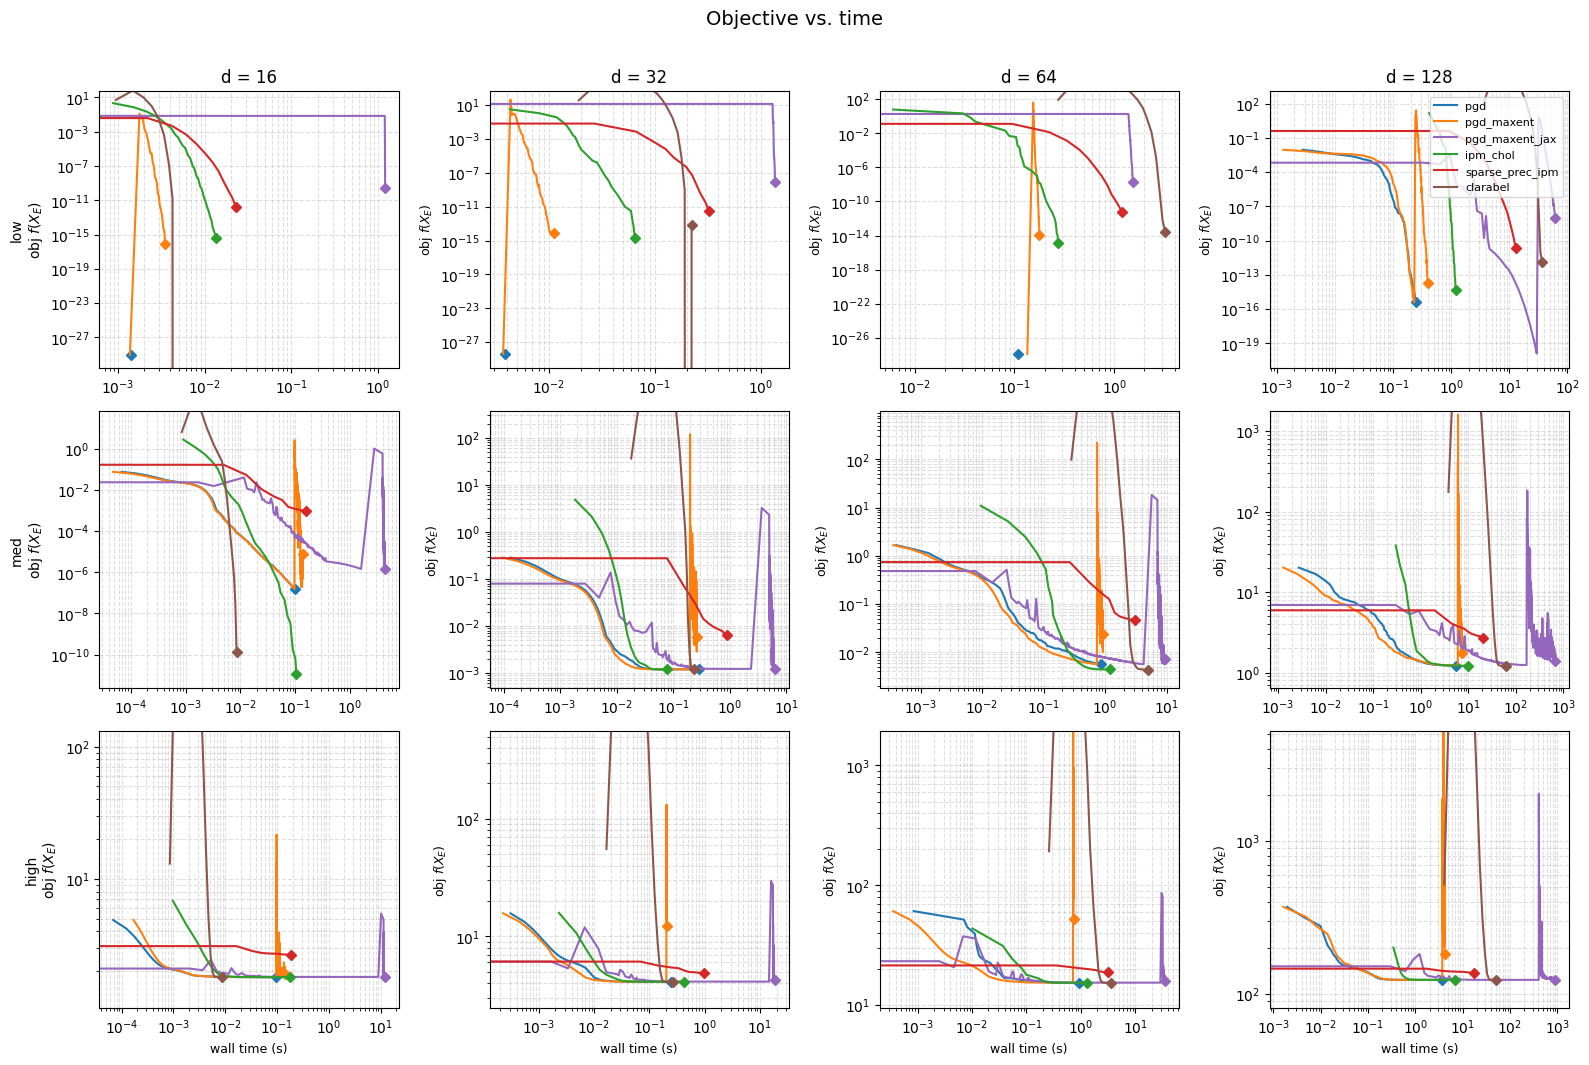

In [11]:
# ── Objective vs. time ────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    len(NOISE_VALS), len(D_VALS),
    figsize=(4 * len(D_VALS), 3.5 * len(NOISE_VALS)),
    sharex=False, sharey=False,
)

for row, noise in enumerate(NOISE_VALS):
    for col, d in enumerate(D_VALS):
        ax = axes[row, col]
        key = (d, noise)
        entry = results.get(key, {})

        max_initial_obj = 1.0
        for name in SOLVER_NAMES:
            sr = entry.get('solvers', {}).get(name)
            if sr is None:
                continue
            c   = COLORS[name]
            t   = [e['time'] for e in sr['hist']]
            obj = [e['obj']  for e in sr['hist']]
            ax.loglog(t, obj, label=name, color=c)
            ax.loglog([t[-1]], [obj[-1]], color=c, marker='D', markersize=5, linestyle='none')
            max_initial_obj = max(max_initial_obj, obj[0])
        ax.set_ylim(top=max_initial_obj * 10)

        if row == 0:
            ax.set_title(f'd = {d}', fontsize=12)
        if col == 0:
            ax.set_ylabel(f'{noise}\n' + r'obj $f(X_E)$', fontsize=10)
        else:
            ax.set_ylabel(r'obj $f(X_E)$', fontsize=9)
        if row == len(NOISE_VALS) - 1:
            ax.set_xlabel('wall time (s)', fontsize=9)
        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        if row == 0 and col == len(D_VALS) - 1:
            ax.legend(fontsize=8, loc='upper right')

fig.suptitle('Objective vs. time', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

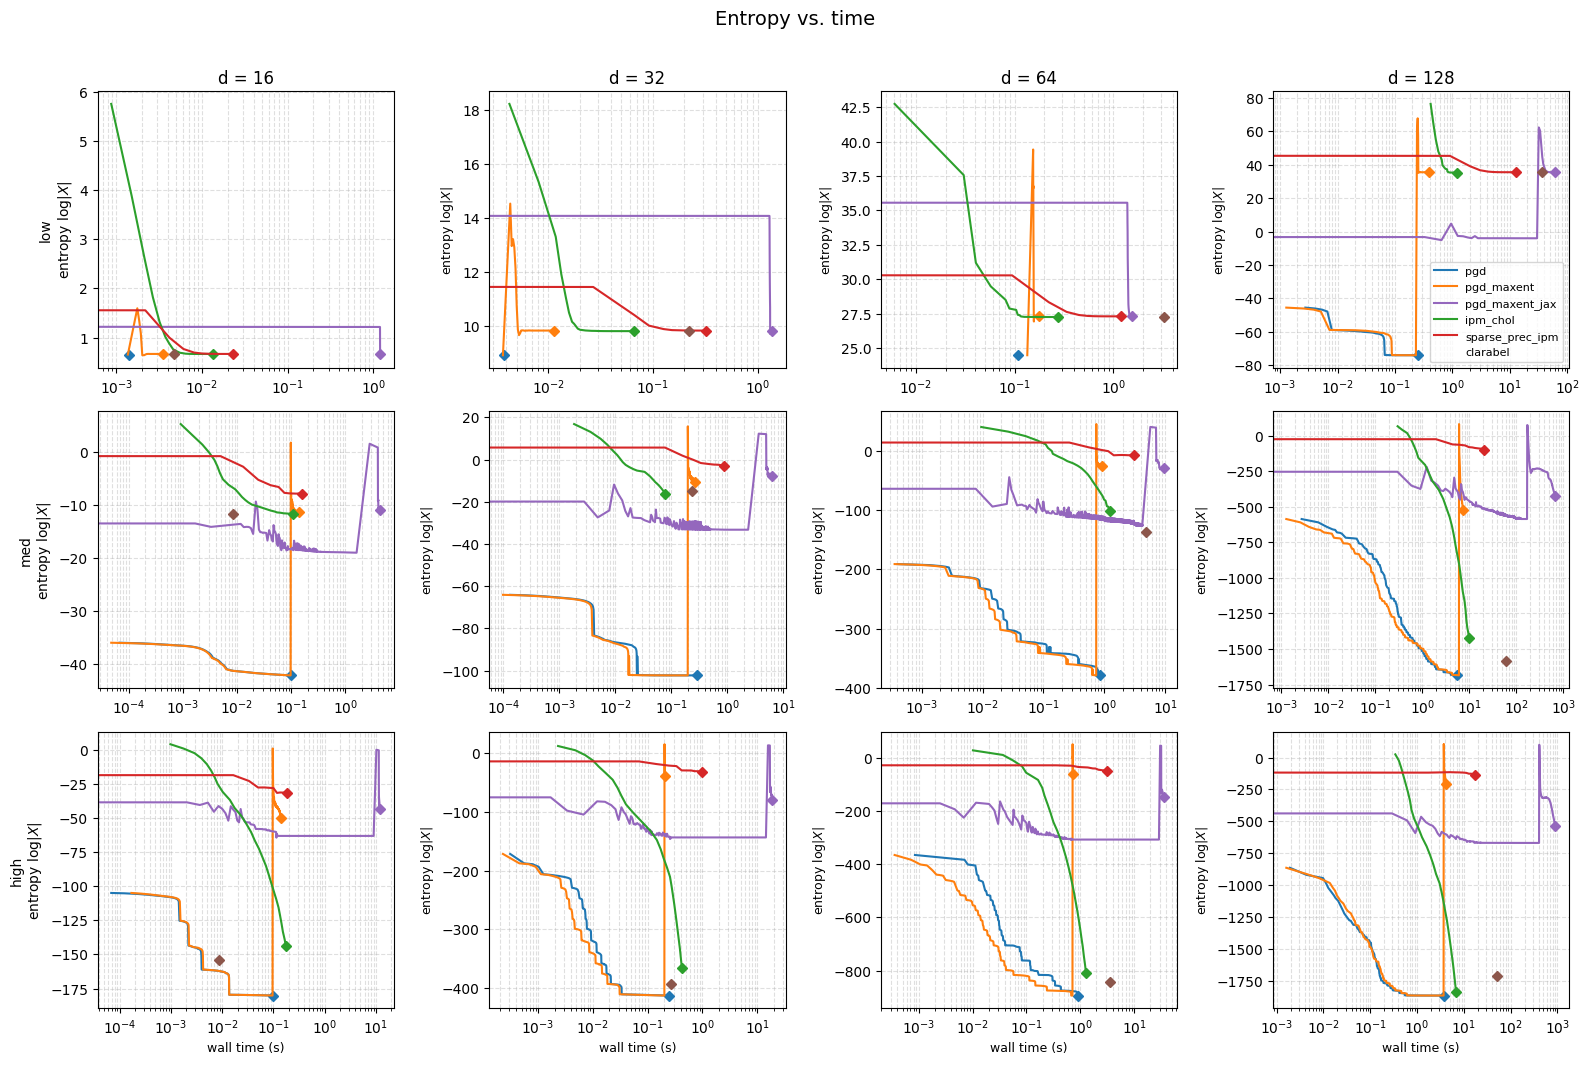

In [3]:
# ── Entropy vs. time ──────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    len(NOISE_VALS), len(D_VALS),
    figsize=(4 * len(D_VALS), 3.5 * len(NOISE_VALS)),
    sharex=False, sharey=False,
)

for row, noise in enumerate(NOISE_VALS):
    for col, d in enumerate(D_VALS):
        ax = axes[row, col]
        key = (d, noise)
        entry = results.get(key, {})

        for name in SOLVER_NAMES:
            sr = entry.get('solvers', {}).get(name)
            if sr is None:
                continue
            c = COLORS[name]
            ent_pairs = [(e['time'], e['entropy']) for e in sr['hist']
                         if not np.isnan(e['entropy'])]
            if not ent_pairs:
                continue
            te, ent = zip(*ent_pairs)
            ax.semilogx(te, ent, label=name, color=c,
                        linestyle='none' if len(ent_pairs) == 1 else '-')
            ax.semilogx([te[-1]], [ent[-1]], color=c, marker='D', markersize=5, linestyle='none')

        if row == 0:
            ax.set_title(f'd = {d}', fontsize=12)
        if col == 0:
            ax.set_ylabel(f'{noise}\n' + r'entropy $\log|X|$', fontsize=10)
        else:
            ax.set_ylabel(r'entropy $\log|X|$', fontsize=9)
        if row == len(NOISE_VALS) - 1:
            ax.set_xlabel('wall time (s)', fontsize=9)
        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        if row == 0 and col == len(D_VALS) - 1:
            ax.legend(fontsize=8, loc='lower right')

fig.suptitle('Entropy vs. time', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [4]:
# ── Summary table ─────────────────────────────────────────────────────────────
# Final obj, entropy, frob_err, wall time, and compile_time for each (d, noise, solver).

rows = []
for noise in NOISE_VALS:
    for d in D_VALS:
        key = (d, noise)
        entry = results.get(key, {})
        Sigma_true = entry.get('problem', {}).get('Sigma_true')
        for name in SOLVER_NAMES:
            sr = entry.get('solvers', {}).get(name)
            if sr is None:
                rows.append((d, noise, name, float('nan'), float('nan'), float('nan'), float('nan'), float('nan')))
                continue
            last  = sr['hist'][-1]
            S_hat = sr['Sigma_hat']
            frob  = float(np.linalg.norm(S_hat - Sigma_true, 'fro')) if Sigma_true is not None else float('nan')
            ct    = sr.get('compile_time') or float('nan')
            rows.append((d, noise, name, last['obj'], last['entropy'], frob, last['time'], ct))

print(f"{'d':>4}  {'noise':<5}  {'solver':<20}  {'obj':>10}  {'entropy':>10}  {'frob_err':>10}  {'time(s)':>8}  {'compile(s)':>10}")
print('-' * 95)
prev = None
for d, noise, name, obj, ent, frob, t, ct in rows:
    if (d, noise) != prev:
        if prev is not None:
            print()
        prev = (d, noise)
    ct_str = f"{ct:>10.2f}" if ct == ct else f"{'—':>10}"
    print(f"{d:>4}  {noise:<5}  {name:<20}  {obj:>10.3e}  {ent:>10.3f}  {frob:>10.3f}  {t:>8.3f}  {ct_str}")

   d  noise  solver                       obj     entropy    frob_err   time(s)  compile(s)
-----------------------------------------------------------------------------------------------
  16  low    pgd                    9.537e-30       0.655       2.110     0.001           —
  16  low    pgd_maxent             7.729e-17       0.667       2.113     0.003           —
  16  low    pgd_maxent_jax         2.523e-10       0.667       2.113     1.207        0.36
  16  low    ipm_chol               4.102e-16       0.667       2.116     0.013           —
  16  low    sparse_prec_ipm        1.649e-12       0.667       2.113     0.023        5.06
  16  low    clarabel              -1.421e-14       0.667       2.115     0.005           —

  32  low    pgd                    3.997e-29       8.928       9.404     0.004           —
  32  low    pgd_maxent             8.301e-15       9.840       8.692     0.011           —
  32  low    pgd_maxent_jax         8.124e-09       9.840       8.692     1